In [1]:
import numpy as np
import matplotlib.pyplot as plt
from abc import ABC, abstractmethod


# ----------------------------------------------------------------------
# Estrategias
# ----------------------------------------------------------------------

class BohmStrategy(ABC):
    @abstractmethod
    def resolve(self, **kwargs):
        pass


class AdvectionDispersionStrategy(BohmStrategy):
    """
    ADR 1D vectorizada sobre simulaciones.
    Acepta v y D como escalares o arrays de tamaño nsims.
    Devuelve 'concentration' de shape (nsims, nx) o (nx,) si nsims==1.
    """

    def resolve(self, L=100, T=10, dx=1, dt=0.1,
                v=1, D=0.1, C0=1, source_index=0, snapshots=10):

        v = np.atleast_1d(np.asarray(v, dtype=float))
        D = np.atleast_1d(np.asarray(D, dtype=float))

        nsims = max(v.size, D.size)
        v = np.broadcast_to(v, (nsims,)).astype(float).copy()
        D = np.broadcast_to(D, (nsims,)).astype(float).copy()

        nx = int(round(L / dx)) + 1
        nt = int(round(T / dt)) + 1

        alpha = (D * dt / dx**2)[:, None]      # (nsims, 1)
        beta  = (v * dt / dx)[:, None]         # (nsims, 1)

        if np.any(alpha + beta / 2 > 0.5):
            raise ValueError("Esquema inestable")

        x = np.arange(nx) * dx

        C = np.zeros((nsims, nx))
        C[:, source_index] = C0

        every = max(1, nt // snapshots)
        history = {0.0: C.copy()}

        for step in range(1, nt):
            C_new = np.zeros_like(C)
            C_new[:, 1:-1] = (
                C[:, 1:-1]
                + alpha * (C[:, 2:] - 2.0 * C[:, 1:-1] + C[:, :-2])
                - beta  * (C[:, 1:-1] - C[:, :-2])
            )
            C_new[:, 0] = C0
            C = C_new

            if step % every == 0 or step == nt - 1:
                history[step * dt] = C.copy()

        times = np.array(list(history.keys()))

        if nsims == 1:
            return {
                "x": x,
                "time": times,
                "snapshots": {k: s[0] for k, s in history.items()},
                "concentration": C[0],
            }

        return {
            "x": x,
            "time": times,
            "snapshots": history,               # dict {t: (nsims, nx)}
            "concentration": C,                 # (nsims, nx)
            "mean": C.mean(axis=0),
            "std":  C.std(axis=0),
            "min":  C.min(axis=0),
            "max":  C.max(axis=0),
            "v": v,
            "D": D,
        }


class MonteCarloStrategy(BohmStrategy):
    """Ya estaba vectorizada; solo pequeños ajustes de consistencia."""

    def __init__(self):
        self.base = AdvectionDispersionStrategy()

    def sample(self, spec, n, rng):
        if callable(spec):
            return np.array([spec(rng) for _ in range(n)], dtype=float)

        if isinstance(spec, dict):
            dist = spec["distribution"].lower()
            if dist == "normal":
                return rng.normal(spec["mean"], spec["std"], n)
            if dist == "uniform":
                return rng.uniform(spec["low"], spec["high"], n)
            if dist == "lognormal":
                return rng.lognormal(spec["mean"], spec["sigma"], n)
            if dist == "constant":
                return np.full(n, spec["value"], dtype=float)
            raise ValueError("Distribución no soportada")

        if isinstance(spec, (list, tuple, np.ndarray)):
            return np.resize(np.asarray(spec, dtype=float), n)

        return np.full(n, float(spec))

    def resolve(self, simulations=1000, seed=None, return_all=False,
                distributions=None, **kwargs):

        rng = np.random.default_rng(seed)
        distributions = distributions or {}

        L  = kwargs.get("L", 100)
        T  = kwargs.get("T", 10)
        dx = kwargs.get("dx", 1)
        dt = kwargs.get("dt", 0.1)
        C0 = kwargs.get("C0", 1)
        source_index = kwargs.get("source_index", 0)
        snapshots = kwargs.get("snapshots", 10)

        v = self.sample(distributions.get("v", kwargs.get("v", 1)), simulations, rng)
        D = self.sample(distributions.get("D", kwargs.get("D", 0.1)), simulations, rng)

        # Delegamos en la estrategia vectorizada
        out = self.base.resolve(
            L=L, T=T, dx=dx, dt=dt, C0=C0,
            source_index=source_index, snapshots=snapshots,
            v=v, D=D,
        )

        result = {
            "x": out["x"],
            "mean": out["mean"],
            "std":  out["std"],
            "min":  out["min"],
            "max":  out["max"],
            "time": out["time"],
            "snapshots": out["snapshots"],
        }
        if return_all:
            result["results"] = out["concentration"]

        return result


# ----------------------------------------------------------------------
# Facade
# ----------------------------------------------------------------------

class BohmFacade:

    def __init__(self, mode="bohm", **kwargs):
        self.mode = mode.lower()
        if self.mode == "bohm":
            self.strategy = AdvectionDispersionStrategy()
        elif self.mode == "montecarlo":
            self.strategy = MonteCarloStrategy()
        else:
            raise ValueError("Modo no soportado")
        self.defaults = kwargs

    def resolve(self, **kwargs):
        params = {**self.defaults, **kwargs}

        list_params = {
            k: v for k, v in params.items()
            if isinstance(v, (list, tuple, np.ndarray))
        }

        # ⚡ Producto cartesiano vectorizado: una sola llamada a la estrategia
        if list_params and self.mode == "bohm":
            keys   = list(list_params.keys())
            arrays = [np.asarray(params[k], dtype=float).ravel() for k in keys]
            grids  = np.meshgrid(*arrays, indexing="ij")
            for k, g in zip(keys, grids):
                params[k] = g.ravel()

        return self.strategy.resolve(**params)


# ----------------------------------------------------------------------
# Instancias por defecto (igual que antes)
# ----------------------------------------------------------------------

bohm = BohmFacade("bohm", L=100, T=10, dx=1, dt=0.1, v=1, D=0.1)
mc   = BohmFacade("montecarlo")

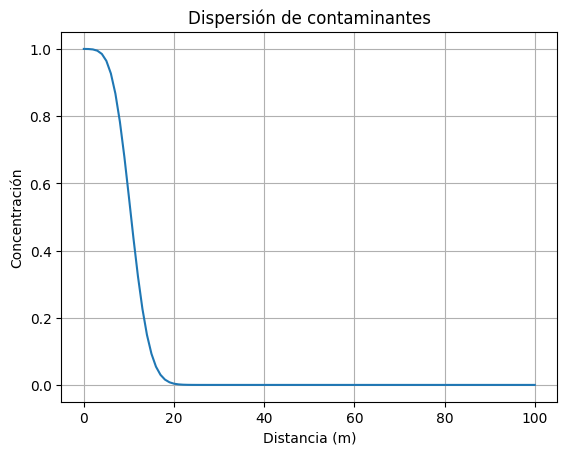

In [2]:
resultado = bohm.resolve()

plt.plot(
    resultado["x"],
    resultado["concentration"]
)

plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")

plt.title(
    "Dispersión de contaminantes"
)

plt.grid()
plt.show()

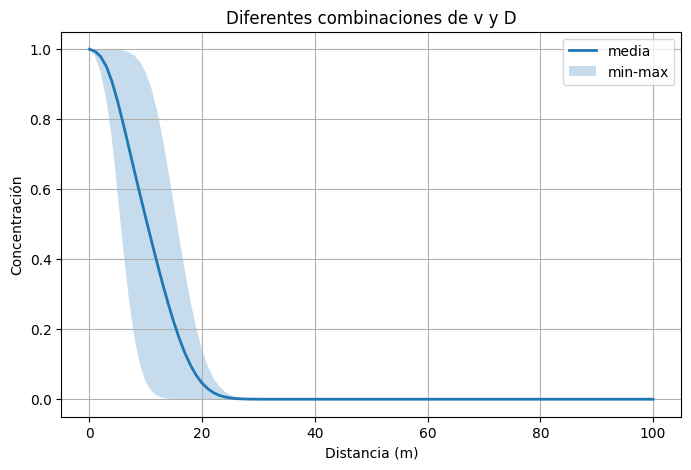

In [4]:
resultados = bohm.resolve(v=[0.5, 1, 1.5], D=[0.1, 0.2])

x = resultados["x"]

plt.figure(figsize=(8, 5))
plt.plot(x, resultados["mean"], label="media", lw=2)
plt.fill_between(x, resultados["min"], resultados["max"],
                 alpha=0.25, label="min-max")
plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")
plt.title("Diferentes combinaciones de v y D")
plt.grid()
plt.legend()
plt.show()

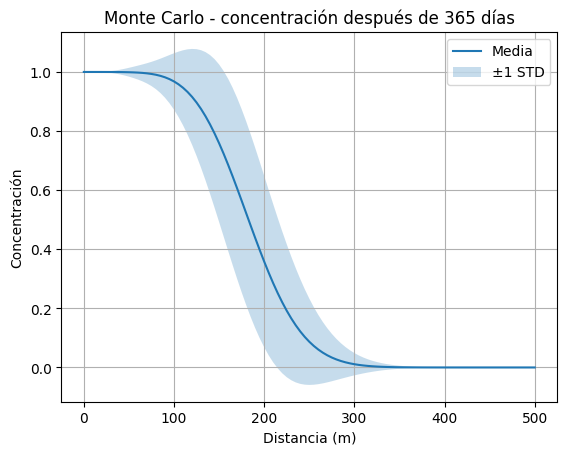

In [5]:
resultado_mc = mc.resolve(
    simulations=1000,
    seed=42,
    L=500,
    T=365,
    dx=5,
    dt=0.1,
    C0=1,
    distributions={

        "D": {
            "distribution": "normal",
            "mean": 0.1,
            "std": 0.02
        },

        "v": {
            "distribution": "normal",
            "mean": 0.5,
            "std": 0.1
        }

    },
    return_all=True
)

x = resultado_mc["x"]

plt.plot(
    x,
    resultado_mc["mean"],
    label="Media"
)

plt.fill_between(
    x,
    resultado_mc["mean"]
    - resultado_mc["std"],

    resultado_mc["mean"]
    + resultado_mc["std"],

    alpha=0.25,
    label="±1 STD"
)

plt.xlabel("Distancia (m)")
plt.ylabel("Concentración")

plt.title(
    "Monte Carlo - concentración después de 365 días"
)

plt.legend()
plt.grid()

plt.show()

In [6]:
probabilidad = np.mean(
    resultado_mc["results"][:, -1] > 0
)

print(
    "Probabilidad de que el contaminante alcance el final:",
    probabilidad
)

Probabilidad de que el contaminante alcance el final: 0.0
